# Side by side

All six classifiers on the same two-moons training points, scored on the same held-out
points. These are the numbers behind the dashboard's scorecard.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml8 import data, models, scratch, plotting as P
P.use_style()
pd.set_option("display.precision", 4)

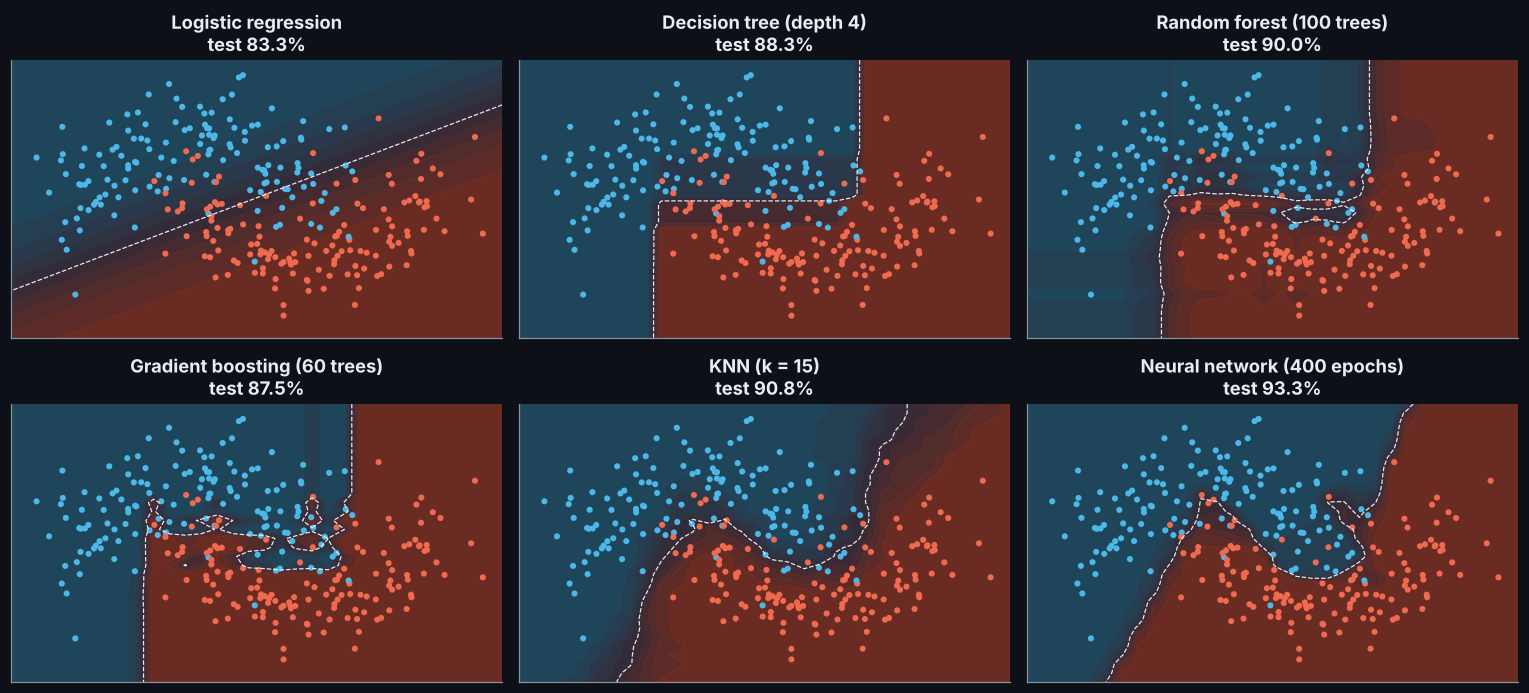

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
mlp, hist, surf = models.train_mlp(Xtr, ytr, X_test=Xte, y_test=yte)
fitted = {
    "Logistic regression": models.logistic_2d().fit(Xtr, ytr),
    "Decision tree (depth 4)": models.tree(4).fit(Xtr, ytr),
    "Random forest (100 trees)": models.forest(100).fit(Xtr, ytr),
    "Gradient boosting (60 trees)": models.boosting(60).fit(Xtr, ytr),
    "KNN (k = 15)": models.knn(15).fit(Xtr, ytr),
    "Neural network (400 epochs)": mlp,
}
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
for ax, (name, m) in zip(axes.ravel(), fitted.items()):
    P.plot_surface(ax, m, Xtr, ytr, title=f"{name}\ntest {m.score(Xte, yte):.1%}")
plt.tight_layout()

In [3]:
table = pd.DataFrame({name: {"train accuracy": m.score(Xtr, ytr), "test accuracy": m.score(Xte, yte),
                             "train − test gap": m.score(Xtr, ytr) - m.score(Xte, yte)} for name, m in fitted.items()}).T
table.sort_values("test accuracy", ascending=False)

,train accuracy,test accuracy,train − test gap
Neural network (400 epochs),0.9571,0.9333,0.0238
KNN (k = 15),0.9250,0.9083,0.0167
Random forest (100 trees),0.9714,0.9000,0.0714
Decision tree (depth 4),0.9179,0.8833,0.0345
Gradient boosting (60 trees),1.0000,0.8750,0.1250
Logistic regression,0.8607,0.8333,0.0274


With 120 test points, one point is 0.83 percentage points, so gaps of one or two points
between models are within noise. The clear signals are the linear model's ceiling and
boosting's large train–test gap at 60 trees.

## When to reach for which

| Algorithm | Family | Strength | Watch out for |
|---|---|---|---|
| Linear regression | Linear | Fast, interpretable coefficients | Only straight-line relationships |
| Logistic regression | Linear | Calibrated probabilities, strong baseline | Linear boundary unless you engineer features |
| Decision tree | Tree | Readable rules, no scaling needed | Overfits as it deepens |
| Random forest | Tree | Robust default for tabular data | Larger, slower, less interpretable |
| Gradient boosting | Tree | Often the most accurate on tabular data | Needs tuning of trees and learning rate |
| KNN | Distance | No training, simple | Slow at prediction time; needs scaled features |
| K-means | Distance | Quick clustering | You choose *k*; assumes round clusters |
| Neural network | Neural | Learns any boundary given data | Needs data, tuning and compute |